# DeepPCB – EDA

1. Check data structure
2. Check for duplicate images
3. Layer distribution and number of boxes
4. Pixel and outlier image statistics
5. Review image sizes

In [6]:
import hashlib
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image

try:
    from IPython.display import display
except ImportError:
    display = print

RANDOM_SEED = 42
DATA_ROOT = Path(os.environ.get("PCB_DATA_ROOT", Path.cwd() / "Data" / "raw_data")).expanduser()
OUT_DIR = Path("outputs") / "eda"
SPLITS = ("train", "valid", "test")
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png"}
CLASS_ID_BASE = 1
SMALL_AREA = 32 * 32

rng = np.random.default_rng(RANDOM_SEED)
OUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def display_path(path):
    try:
        return str(Path(path).resolve().relative_to(Path.cwd()))
    except ValueError:
        return str(path)


ROOT = next((c for c in (DATA_ROOT, DATA_ROOT / "DeepPCB") if (c / "Class.txt").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(f"Class.txt not found in {DATA_ROOT} or {DATA_ROOT / 'DeepPCB'}")

CLASS_NAMES = [
    n.strip(" '\"")
    for n in (ROOT / "Class.txt").read_text(encoding="utf-8").strip().split(",")
    if n.strip(" '\"")
]

assert len(CLASS_NAMES) == 6, f"Expected 6 classes, but found: {CLASS_NAMES}"

print("Data root:", display_path(ROOT))
print("Class ID", {i + CLASS_ID_BASE: n for i, n in enumerate(CLASS_NAMES)})

Data root: Data\raw_data
Class ID {1: 'open', 2: 'short', 3: 'mousebite', 4: 'spur', 5: 'copper', 6: 'pin-hole'}


- The dataset is a collection of PCB defect images that have already been split into train/valid/test sets.

- Each split contains an images folder with the images and a labels folder with the labels of the defects in the images.

- Class.txt is a file containing the defect classifications.

- There are 6 types of defects: Open, Short, Mousebite, Spur, Copper, Pinhole.

## 1. Check the data structure

Check if the images and labels match each other

Are the image sizes consistent

Are the labels valid

In [7]:
image_rows, box_rows, problems = [], [], []
label_files = {}


def add_problem(split, file, issue, detail=""):
    problems.append({"split": split, "file": file, "issue": issue, "detail": detail})


for split in SPLITS:
    img_dir, lbl_dir = ROOT / split / "images", ROOT / split / "labels"
    if not (img_dir.is_dir() and lbl_dir.is_dir()):
        raise FileNotFoundError(f"Missing images/labels in {display_path(ROOT / split)}")

    image_paths = sorted(p for p in img_dir.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES)
    stems = {p.stem for p in image_paths}
    label_paths = list(lbl_dir.glob("*.txt"))
    label_files[split] = len(label_paths)

    for lp in label_paths:
        if lp.stem not in stems:
            add_problem(split, lp.name, "Label without corresponding image")

    for ip in image_paths:
        try:
            with Image.open(ip) as im:
                im.load()
                width, height = im.size
                mode = im.mode
        except Exception as error:
            add_problem(split, ip.name, "Unreadable image", str(error))
            continue

        n_boxes = 0
        lp = lbl_dir / f"{ip.stem}.txt"
        if not lp.is_file():
            add_problem(split, ip.name, "Image without label file")
        else:
            for line_no, line in enumerate(lp.read_text(encoding="utf-8").splitlines(), start=1):
                if not line.strip():
                    continue

                parts = line.split()
                where = f"{lp.name}:{line_no}"

                if len(parts) != 5:
                    add_problem(split, where, "Invalid number of fields", line)
                    continue

                try:
                    x1, y1, x2, y2, cid = map(int, parts)
                except ValueError:
                    add_problem(split, where, "Non-integer value", line)
                    continue

                cidx = cid - CLASS_ID_BASE
                if not 0 <= cidx < len(CLASS_NAMES):
                    add_problem(split, where, "Unknown class ID", line)
                elif x2 <= x1 or y2 <= y1:
                    add_problem(split, where, "Degenerate bounding box", line)
                elif x1 < 0 or y1 < 0 or x2 > width or y2 > height:
                    add_problem(split, where, "Bounding box outside image", line)
                else:
                    n_boxes += 1
                    box_rows.append({
                        "split": split,
                        "image_name": ip.name,
                        "image_key": f"{split}/{ip.name}",
                        "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                        "w": x2 - x1,
                        "h": y2 - y1,
                        "area": (x2 - x1) * (y2 - y1),
                        "class_id": cid,
                        "class_idx": cidx,
                        "class_name": CLASS_NAMES[cidx],
                    })

        image_rows.append({
            "split": split,
            "image_name": ip.name,
            "image_key": f"{split}/{ip.name}",
            "image_path": ip,
            "width": width,
            "height": height,
            "mode": mode,
            "n_boxes": n_boxes,
        })

manifest = pd.DataFrame(image_rows)
annotations = pd.DataFrame(box_rows)
problems_df = pd.DataFrame(problems, columns=["split", "file", "issue", "detail"])

assert not manifest.empty and not annotations.empty, "No images or bounding boxes could be loaded"

inventory = manifest.groupby("split").agg(
    images=("image_name", "size"),
    boxes=("n_boxes", "sum"),
    images_no_box=("n_boxes", lambda s: int((s == 0).sum())),
).reindex(SPLITS)

inventory.insert(1, "label_files", pd.Series(label_files))
display(inventory)

print("Image dimensions (width x height):")
display(manifest.groupby(["width", "height"]).size().rename("images").to_frame())

print("Original image modes:")
display(manifest["mode"].value_counts().rename("images").to_frame())

dup_names = manifest.groupby("image_name")["split"].nunique()

print(f"Duplicate filenames across splits: {int((dup_names > 1).sum())}")
print(f"Structural/annotation issues: {len(problems_df)}")

if len(problems_df):
    display(problems_df.groupby("issue").size().rename("count").to_frame())
    display(problems_df.head(20))


,images,label_files,boxes,images_no_box
split,,,,
train,1199,1199,8015,0
valid,150,150,1005,0
test,150,150,984,0


Image dimensions (width x height):


,,images
width,height,
640,640,1499


Original image modes:


,images
mode,
L,1462
RGB,37


Duplicate filenames across splits: 0
Structural/annotation issues: 0


- The dataset has 1,500 images (640×640, a single size) and 10,013 boxes
- The number of images in train/valid/test is 1200/150/150 respectively. The split ratio for train/val/test is fine
- No structural errors or label errors, no images missing labels
- No images have duplicate names across the splits
- In the entire dataset, there are 38 RGB images, the rest are L mode -> check the images again to see if the image mode is correctly determined

## 2. Check for Duplicate Images
Use SHA-256 to see if there are duplicate images across the splits.

Hash the pixels to check if there are images with the same content but saved in different formats/modes. For each group of duplicates, compare the labels to see if the copies have the same labels.

In [8]:
byte_hash, pixel_hash = [], []
for row in manifest.itertuples():
    byte_hash.append(hashlib.sha256(row.image_path.read_bytes()).hexdigest())
    with Image.open(row.image_path) as im:
        rgb = np.asarray(im.convert("RGB"))
    pixel_hash.append(hashlib.sha256(rgb.tobytes() + str(rgb.shape).encode()).hexdigest())

manifest["sha256"] = byte_hash
manifest["pixel_hash"] = pixel_hash

label_sig = {
    key: tuple(sorted(zip(g["x1"], g["y1"], g["x2"], g["y2"], g["class_id"])))
    for key, g in annotations.groupby("image_key")
}

dup_rows = []
for _, g in manifest.groupby("pixel_hash"):
    if len(g) < 2:
        continue
    keys = list(g["image_key"])
    dup_rows.append({
        "images": ", ".join(keys),
        "n_images": len(g),
        "splits": ", ".join(sorted(set(g["split"]))),
        "cross_split": g["split"].nunique() > 1,
        "byte_identical": g["sha256"].nunique() == 1,
        "same_labels": len({label_sig.get(k, ()) for k in keys}) == 1,
    })

dup_table = pd.DataFrame(
    dup_rows, columns=["images", "n_images", "splits", "cross_split", "byte_identical", "same_labels"]
)

n_dup_groups = len(dup_table)
n_dup_extra = int((dup_table["n_images"] - 1).sum()) if n_dup_groups else 0
n_dup_cross = int(dup_table["cross_split"].sum()) if n_dup_groups else 0
n_dup_byte = int(dup_table["byte_identical"].sum()) if n_dup_groups else 0
n_dup_conflict = int((~dup_table["same_labels"]).sum()) if n_dup_groups else 0
n_byte_groups = int((manifest.groupby("sha256")["image_key"].transform("size") > 1).sum())

print(f"Byte-identical images (SHA-256): {n_byte_groups} images in duplicate groups")
print(f"Pixel-duplicate groups: {n_dup_groups} groups, {n_dup_extra} redundant images | "
      f"across multiple splits: {n_dup_cross} | also byte-identical: {n_dup_byte} | "
      f"inconsistent labels across duplicates: {n_dup_conflict}")

SPLIT_PRIORITY = {name: i for i, name in enumerate(SPLITS)}
dup_remove_keys = []

if n_dup_groups:
    with pd.option_context("display.max_colwidth", None):
        display(dup_table)

    for _, g in manifest.groupby("pixel_hash"):
        if len(g) < 2:
            continue
        ordered = g.assign(_p=g["split"].map(SPLIT_PRIORITY)).sort_values(["_p", "image_name"])
        dup_remove_keys.extend(ordered["image_key"].iloc[1:])  # Keep the first image (prioritize train)

    pd.DataFrame({"image_key": dup_remove_keys}).to_csv(OUT_DIR / "duplicates_to_remove.csv", index=False)
    print(f"Suggested removal of {len(dup_remove_keys)} images -> outputs/eda/duplicates_to_remove.csv")

    shown = dup_table.head(3)
    fig, axes = plt.subplots(len(shown), 2, figsize=(8, 4 * len(shown)), squeeze=False)

    for r, (_, d) in enumerate(shown.iterrows()):
        for c, key in enumerate(d["images"].split(", ")[:2]):
            path = manifest.loc[manifest["image_key"] == key, "image_path"].iloc[0]
            with Image.open(path) as im:
                axes[r, c].imshow(im.convert("L"), cmap="gray", vmin=0, vmax=255)
            axes[r, c].set_title(key, fontsize=9)
            axes[r, c].axis("off")

    fig.suptitle("Examples of duplicate image groups", y=1.0)
    fig.tight_layout()
    plt.show()
else:
    print("No duplicate images found.")

Byte-identical images (SHA-256): 0 images in duplicate groups
Pixel-duplicate groups: 0 groups, 0 redundant images | across multiple splits: 0 | also byte-identical: 0 | inconsistent labels across duplicates: 0
No duplicate images found.


## 3. Layer distribution and box size
Check input size, box size, and the smallest stride of the head

The dataset shows imbalance among the 6 error groups.

In [9]:
SPLIT_COL = "split"
annotations["aspect"] = annotations["w"] / annotations["h"]
annotations["side"] = np.sqrt(annotations["area"])
annotations["is_small"] = annotations["area"] < SMALL_AREA

box_by_class = (annotations.groupby([SPLIT_COL, "class_name"]).size().unstack(0)
                .reindex(index=CLASS_NAMES, columns=SPLITS).fillna(0).astype(int))
box_by_class["total"] = box_by_class.sum(axis=1)
box_by_class["% total"] = (100 * box_by_class["total"] / box_by_class["total"].sum()).round(1)

img_by_class = (annotations.groupby([SPLIT_COL, "class_name"])["image_key"].nunique().unstack(0)
                .reindex(index=CLASS_NAMES, columns=SPLITS).fillna(0).astype(int))

print("Number of bounding boxes by class and split:")
display(box_by_class)

print("Number of images containing each class by split:")
display(img_by_class)

class_totals = box_by_class["total"]
imbalance_ratio = class_totals.max() / class_totals.min()
min_eval_class_boxes = int(box_by_class[["valid", "test"]].min().min())

print(f"Class imbalance ratio (max/min bounding boxes): {imbalance_ratio:.2f} | "
      f"Minimum number of bounding boxes per class in validation/test: {min_eval_class_boxes}")

print("Number of bounding boxes per image by split:")
display(manifest.groupby(SPLIT_COL)["n_boxes"].describe().reindex(SPLITS).round(2))

Number of bounding boxes by class and split:


split,train,valid,test,total,% total
class_name,,,,,
open,1560,189,191,1940,19.4
short,1167,167,170,1504,15.0
mousebite,1580,189,194,1963,19.6
spur,1306,165,153,1624,16.2
copper,1185,148,140,1473,14.7
pin-hole,1217,147,136,1500,15.0


Number of images containing each class by split:


split,train,valid,test
class_name,,,
open,1071,138,134
short,869,117,114
mousebite,1013,126,129
spur,951,119,113
copper,996,125,119
pin-hole,1064,126,124


Class imbalance ratio (max/min bounding boxes): 1.33 | Minimum number of bounding boxes per class in validation/test: 136
Number of bounding boxes per image by split:


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,1199.0,6.68,1.81,1.0,5.0,7.0,8.0,15.0
valid,150.0,6.70,1.85,3.0,5.0,7.0,8.0,13.0
test,150.0,6.56,1.81,1.0,5.0,7.0,8.0,12.0


- The error distribution is quite balanced across all 3 splits  
- The imbalance ratio is only 1.33x, the lowest being copper with 1,474 boxes, and the highest being mousebite with 1,965 boxes  
- The average number of boxes per image is 6.6 boxes/image  
- The class with the fewest boxes in valid/test still has 136 boxes, so the AP per class is stable enough and class weighting is not needed.

## 4. Pixel and Outlier Image Statistics

Check if the image mode is really grayscale or RGB? Is it close to binary? Are there any images with unusual brightness/contrast?

Detect outlier images using IQR

Original image modes: {'L': 1462, 'RGB': 37} | Images with genuinely different color channels: 0
Per-image brightness mean / std (0-255 scale):


mean                                std                           extreme_frac                     
          mean     min   median      max     mean     min   median      max         mean    min median    max
split                                                                                                        
train  166.161  43.332  173.128  254.915  108.306   4.552  115.605  127.400        0.984  0.912  0.987  1.000
valid  162.537  46.184  172.862  250.858  109.078  32.064  114.296  127.270        0.980  0.857  0.985  0.998
test   166.152  36.678  172.134  254.746  106.046   7.911  114.668  127.271        0.985  0.931  0.988  1.000

Training set pooled pixels (single channel): mean=166.16 std=121.01 -> 0-1 scale: mean=0.6516 std=0.4745
Median proportion of pixels <=10 or >=245: 98.7%


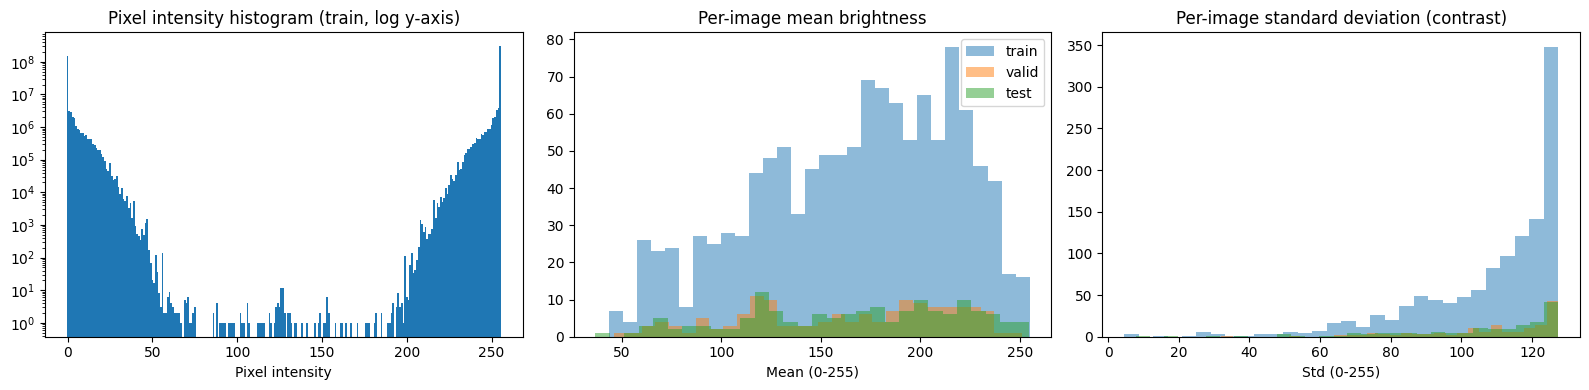

Outlier images (IQR on mean/std or presence of color channels): 44/1499


,image_key,mean,std,extreme_frac,is_color,severity
1087,train/01_PCB__864.jpg,254.92,4.55,1.0,False,7.16
1078,train/01_PCB__855.jpg,254.88,5.39,1.0,False,7.11
1086,train/01_PCB__863.jpg,254.88,5.48,1.0,False,7.10
1376,test/01_PCB__1253.jpg,254.75,7.91,1.0,False,6.94
199,train/01_PCB__1226.jpg,253.92,16.38,1.0,False,6.40
1379,test/01_PCB__1280.jpg,253.59,18.75,1.0,False,6.24
994,train/01_PCB__756.jpg,252.50,24.87,1.0,False,5.85
19,train/01_PCB__1020.jpg,252.03,27.11,1.0,False,5.70
56,train/01_PCB__1062.jpg,252.02,27.19,1.0,False,5.70
1077,train/01_PCB__854.jpg,251.99,27.37,1.0,False,5.69


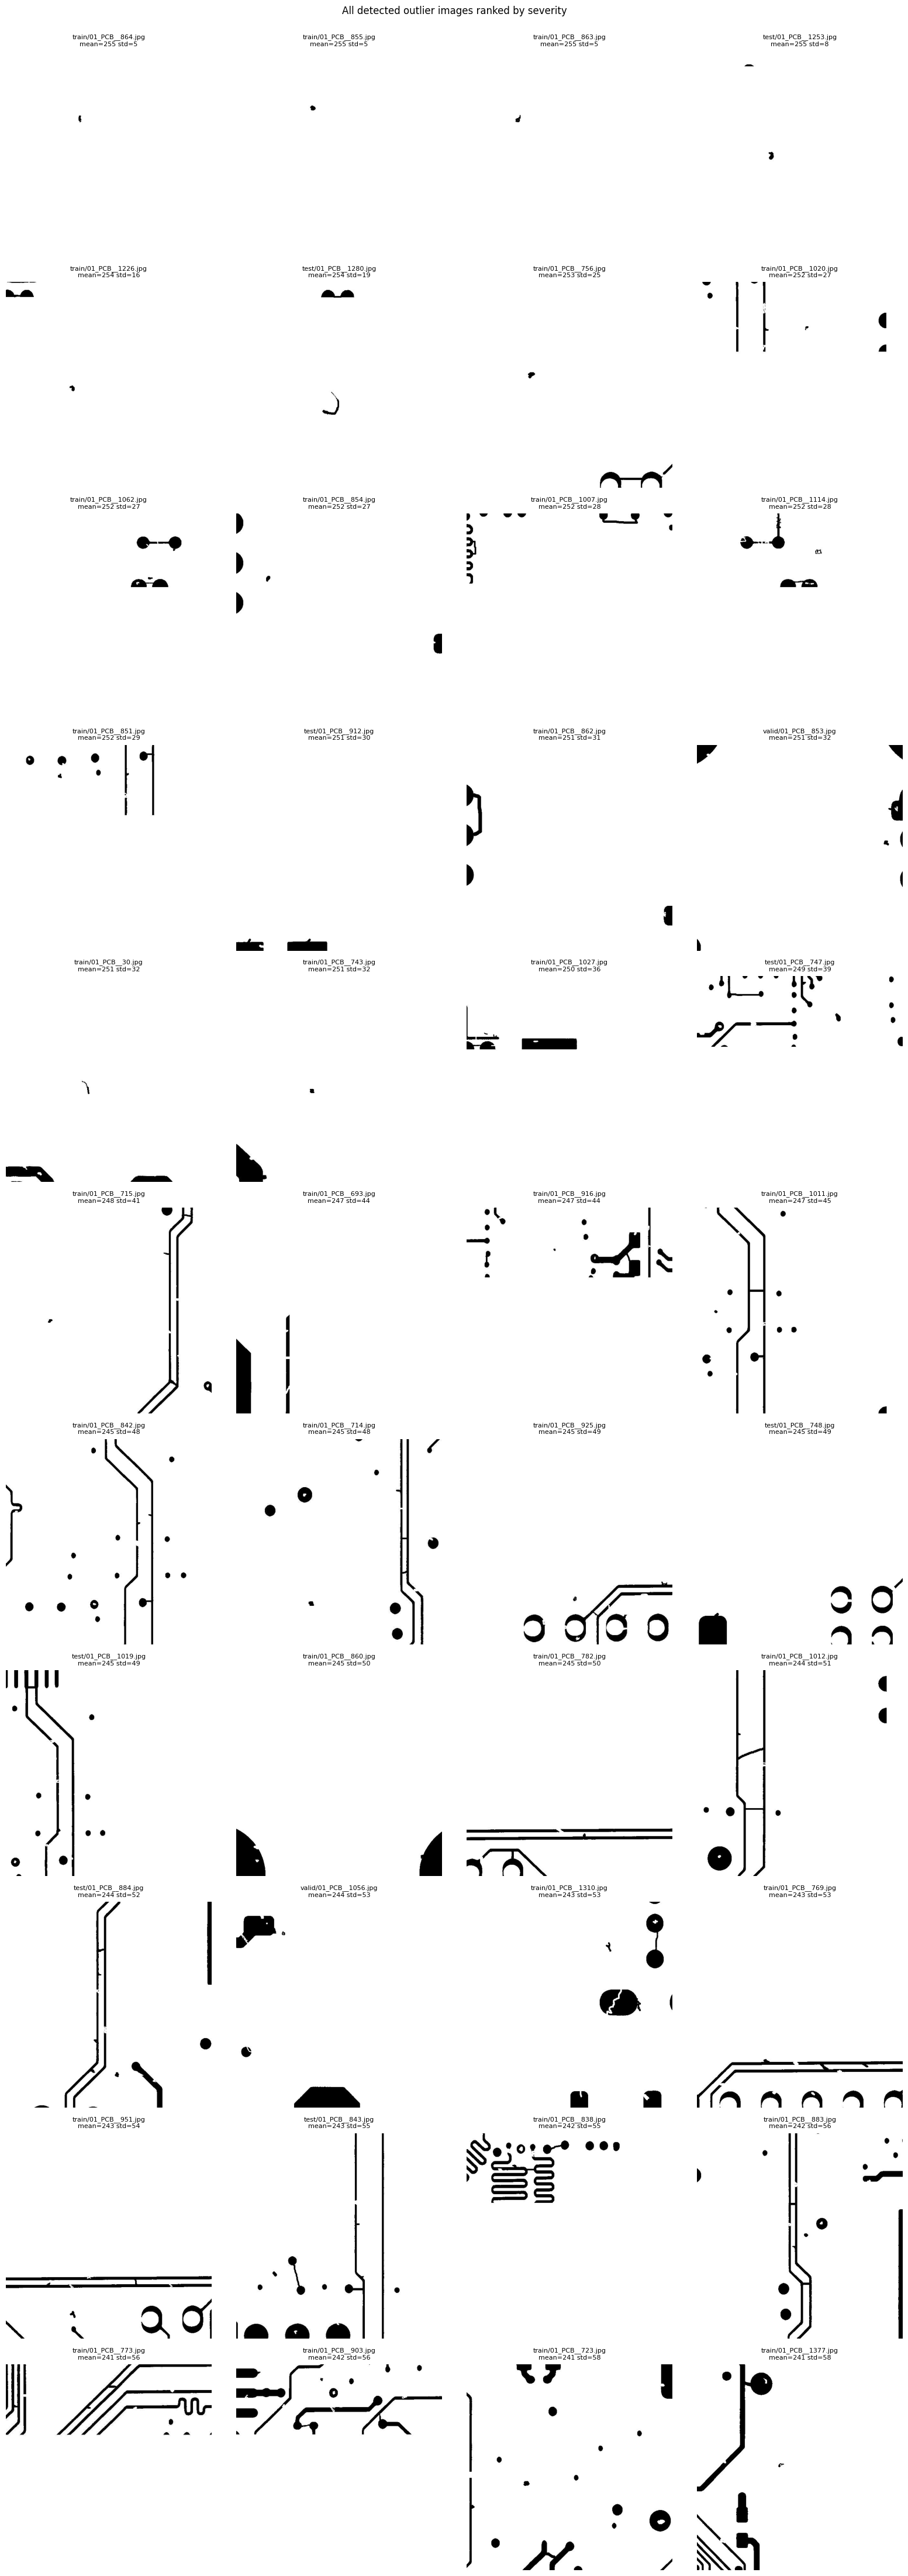

In [10]:
hist_img = np.zeros((len(manifest), 256), dtype=np.int64)
stat_rows = []

for k, row in enumerate(manifest.itertuples()):
    with Image.open(row.image_path) as im:
        rgb = np.asarray(im.convert("RGB"))

    is_color = not (np.array_equal(rgb[..., 0], rgb[..., 1]) and np.array_equal(rgb[..., 1], rgb[..., 2]))
    gray = np.asarray(Image.fromarray(rgb).convert("L")) if is_color else rgb[..., 0]

    hist_img[k] = np.bincount(gray.ravel(), minlength=256)
    stat_rows.append({
        "mean": float(gray.mean()),
        "std": float(gray.std()),
        "extreme_frac": float(((gray <= 10) | (gray >= 245)).mean()),
        "is_color": is_color,
    })

pix = pd.concat([manifest[["split", "image_key"]].reset_index(drop=True), pd.DataFrame(stat_rows)], axis=1)

n_color = int(pix["is_color"].sum())
mode_counts = manifest["mode"].value_counts().to_dict()

print(f"Original image modes: {mode_counts} | Images with genuinely different color channels: {n_color}")
print("Per-image brightness mean / std (0-255 scale):")
display(pix.groupby(SPLIT_COL)[["mean", "std", "extreme_frac"]].agg(["mean", "min", "median", "max"])
        .reindex(SPLITS).round(3))

train_hist = hist_img[(manifest[SPLIT_COL] == "train").to_numpy()].sum(axis=0)
values = np.arange(256)

train_mean = (train_hist * values).sum() / train_hist.sum()
train_std = np.sqrt((train_hist * (values - train_mean) ** 2).sum() / train_hist.sum())
extreme_median = float(pix["extreme_frac"].median())

print(f"Training set pooled pixels (single channel): mean={train_mean:.2f} std={train_std:.2f} "
      f"-> 0-1 scale: mean={train_mean / 255:.4f} std={train_std / 255:.4f}")
print(f"Median proportion of pixels <=10 or >=245: {extreme_median:.1%}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(values, train_hist, width=1.0)
axes[0].set(
    title="Pixel intensity histogram (train, log y-axis)",
    xlabel="Pixel intensity",
    yscale="log"
)

for split in SPLITS:
    sub = pix[pix[SPLIT_COL] == split]
    axes[1].hist(sub["mean"], bins=30, alpha=0.5, label=split)
    axes[2].hist(sub["std"], bins=30, alpha=0.5, label=split)

axes[1].set(title="Per-image mean brightness", xlabel="Mean (0-255)")
axes[2].set(title="Per-image standard deviation (contrast)", xlabel="Std (0-255)")
axes[1].legend()

fig.tight_layout()
plt.show()


def iqr_flag(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)


def robust_z(series):
    med = series.median()
    mad = (series - med).abs().median()
    return (series - med) / (1.4826 * mad + 1e-9)


pix["flag_mean"] = iqr_flag(pix["mean"])
pix["flag_std"] = iqr_flag(pix["std"])
pix["severity"] = np.maximum(robust_z(pix["mean"]).abs(), robust_z(pix["std"]).abs())

outliers = pix[pix["flag_mean"] | pix["flag_std"] | pix["is_color"]].sort_values(
    "severity", ascending=False
)

n_outliers = len(outliers)
print(f"Outlier images (IQR on mean/std or presence of color channels): {n_outliers}/{len(pix)}")

display(outliers[["image_key", "mean", "std", "extreme_frac", "is_color", "severity"]].head(15).round(2))

shown = outliers

if len(shown):
    cols = 4
    rows_n = int(np.ceil(len(shown) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(4 * cols, 4 * rows_n), squeeze=False)

    for ax in axes.ravel():
        ax.axis("off")

    for ax, (_, r) in zip(axes.ravel(), shown.iterrows()):
        path = manifest.loc[manifest["image_key"] == r["image_key"], "image_path"].iloc[0]
        with Image.open(path) as im:
            ax.imshow(
                im.convert("RGB") if r["is_color"] else im.convert("L"),
                cmap="gray", vmin=0, vmax=255
            )
        ax.set_title(f"{r['image_key']}\nmean={r['mean']:.0f} std={r['std']:.0f}", fontsize=8)

    fig.suptitle("All detected outlier images ranked by severity", y=1.0)
    fig.tight_layout()
    plt.show()

- The images are almost binary. 98.7% of the pixels are nearly pure black or white, so brightness/color augmentation is almost meaningless and geometric augmentation should be prioritized.  
- Only one image is truly RGB, which is `train/01_PCB__1030.jpg`.  

Detected 45 outlier images. Among them:  
- 44 images are confirmed as outliers because they have too much white background.  
- 1 image is in the training set but already has bounding boxes and labels, and it’s also the only image in RGB mode.  

=> We need to handle the image `train/01_PCB__1030.jpg` which has the boxes and label text pre-printed on the pixels, so it should be removed from training. The remaining outlier images are valid (boxes align with visible details), they just have a lot of white background, so they can be kept.

## 5. Check image size and box accuracy

Check if the box drawn matches the visible error: Two groups of images: crop around each class' box (for details) and the full image (for context) to see if the labels are reliable enough to train the model.

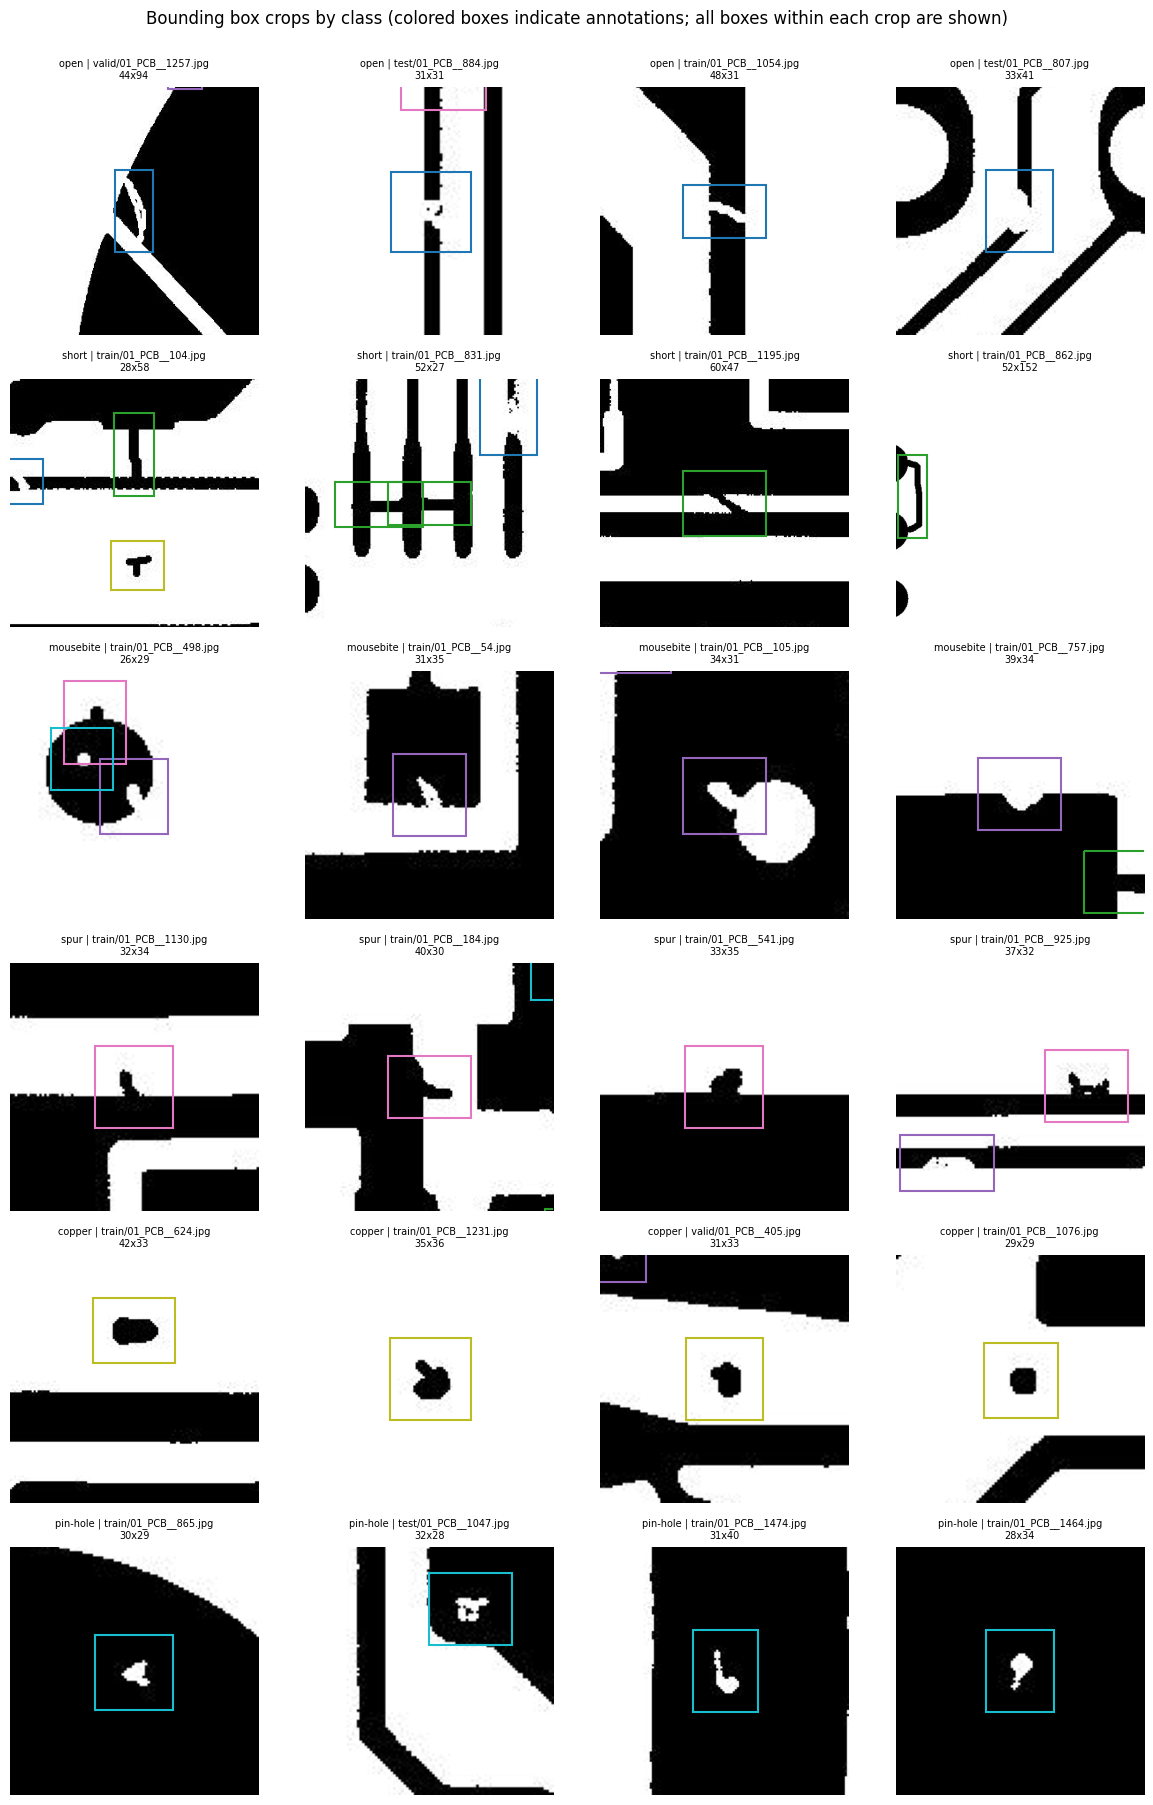

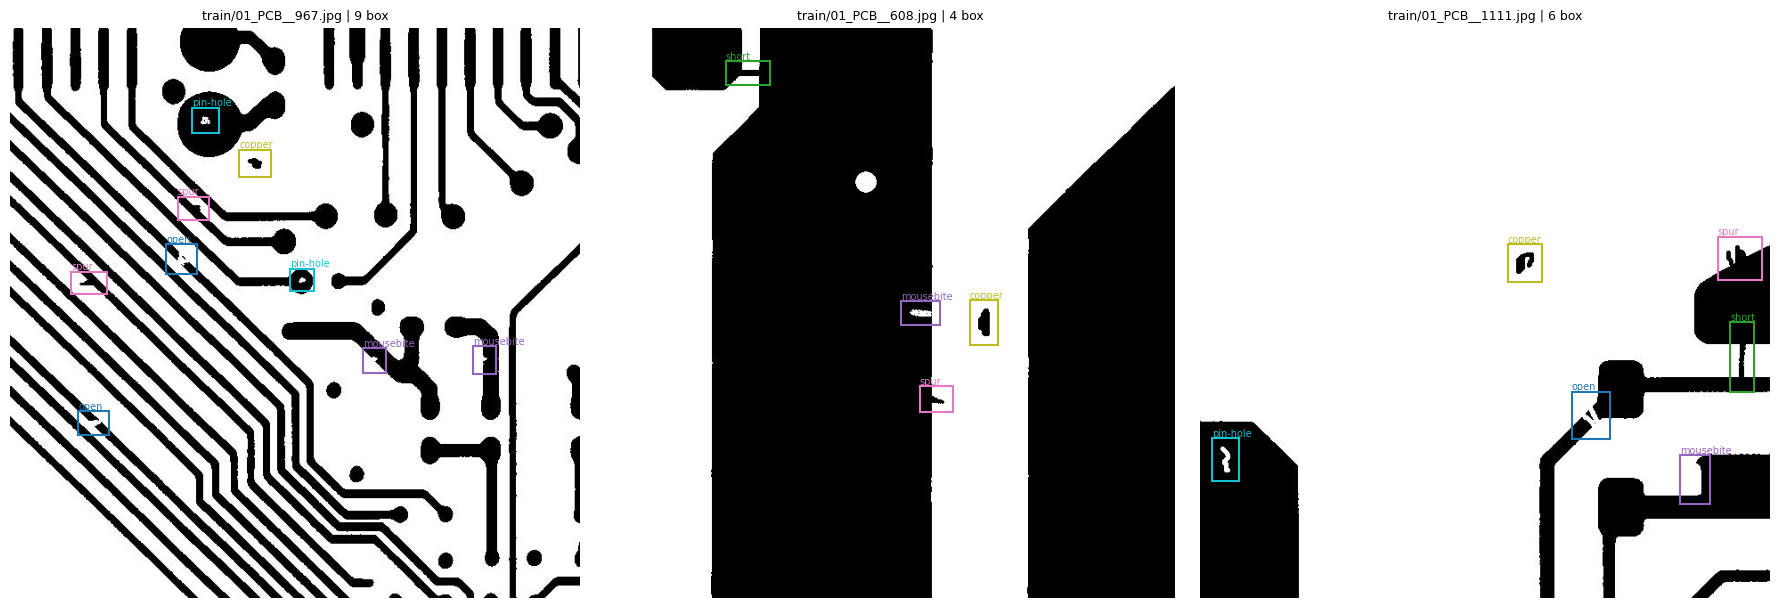

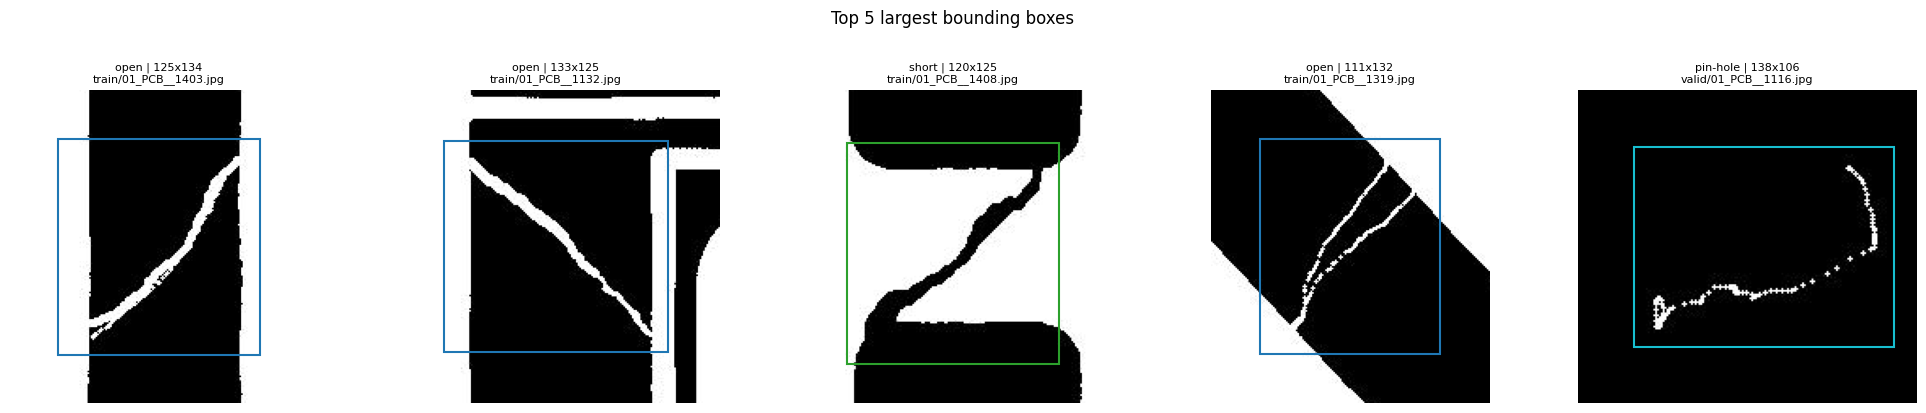

In [ ]:
def load_gray(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("L"))

colors = plt.cm.tab10(np.linspace(0, 1, len(CLASS_NAMES)))

def draw_boxes(ax, boxes, dx=0, dy=0, label=True):
    for b in boxes.itertuples():
        color = colors[b.class_idx]
        ax.add_patch(Rectangle((b.x1 - dx, b.y1 - dy), b.w, b.h, fill=False, edgecolor=color, linewidth=1.5))
        if label:
            ax.text(b.x1 - dx, b.y1 - dy - 2, b.class_name, color=color, fontsize=7)


path_by_key = manifest.set_index("image_key")["image_path"]
PER_CLASS = 4

fig, axes = plt.subplots(len(CLASS_NAMES), PER_CLASS, figsize=(3 * PER_CLASS, 3 * len(CLASS_NAMES)), squeeze=False)

for r, name in enumerate(CLASS_NAMES):
    sub = annotations[annotations["class_name"] == name]
    picks = sub.sample(n=min(PER_CLASS, len(sub)), random_state=RANDOM_SEED)

    for c in range(PER_CLASS):
        ax = axes[r, c]
        ax.axis("off")
        if c >= len(picks):
            continue

        b = picks.iloc[c]
        img = load_gray(path_by_key[b["image_key"]])
        win = int(max(96, 3 * max(b["w"], b["h"])))
        cx, cy = (b["x1"] + b["x2"]) // 2, (b["y1"] + b["y2"]) // 2
        left = int(np.clip(cx - win // 2, 0, max(0, img.shape[1] - win)))
        top = int(np.clip(cy - win // 2, 0, max(0, img.shape[0] - win)))

        ax.imshow(img[top:top + win, left:left + win], cmap="gray", vmin=0, vmax=255,
                  extent=(0, min(win, img.shape[1] - left), min(win, img.shape[0] - top), 0))

        in_win = annotations[(annotations["image_key"] == b["image_key"])
                             & (annotations["x2"] > left) & (annotations["x1"] < left + win)
                             & (annotations["y2"] > top) & (annotations["y1"] < top + win)]

        draw_boxes(ax, in_win, dx=left, dy=top, label=False)
        ax.set_title(f"{name} | {b['image_key']}\n{int(b['w'])}x{int(b['h'])}", fontsize=7)

fig.suptitle("Bounding box crops by class (colored boxes indicate annotations; all boxes within each crop are shown)", y=1.0)
fig.tight_layout()
plt.show()


sample_keys = manifest[manifest[SPLIT_COL] == "train"].sample(n=3, random_state=RANDOM_SEED)["image_key"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, key in zip(axes, sample_keys):
    ax.imshow(load_gray(path_by_key[key]), cmap="gray", vmin=0, vmax=255)
    draw_boxes(ax, annotations[annotations["image_key"] == key])
    ax.set_title(f"{key} | {int(manifest.loc[manifest['image_key'] == key, 'n_boxes'].iloc[0])} box", fontsize=9)
    ax.axis("off")

fig.tight_layout()
plt.show()


largest = annotations.nlargest(5, "area")
fig, axes = plt.subplots(1, len(largest), figsize=(4 * len(largest), 4), squeeze=False)

for ax, (_, b) in zip(axes[0], largest.iterrows()):
    img = load_gray(path_by_key[b["image_key"]])
    pad = 30
    l, t = max(0, int(b["x1"]) - pad), max(0, int(b["y1"]) - pad)
    rgt, bot = min(img.shape[1], int(b["x2"]) + pad), min(img.shape[0], int(b["y2"]) + pad)

    ax.imshow(img[t:bot, l:rgt], cmap="gray", vmin=0, vmax=255, extent=(0, rgt - l, bot - t, 0))
    ax.add_patch(Rectangle((b["x1"] - l, b["y1"] - t), b["w"], b["h"], fill=False,
                           edgecolor=colors[int(b["class_idx"])], linewidth=1.5))

    ax.set_title(f"{b['class_name']} | {int(b['w'])}x{int(b['h'])}\n{b['image_key']}", fontsize=8)
    ax.axis("off")

fig.suptitle("Top 5 largest bounding boxes", y=1.02)
fig.tight_layout()
plt.show()

- Bounding boxes vary in size. The median box edge is 34.4 px, p05 is 27.5 px, and 32.0% of boxes are smaller than 32×32 px. -> maybe try cropping according to the boxes so the classification model can learn the errors better
- Boxes fit the errors accurately, no problem with marking the wrong error spots

Check image quality if resized

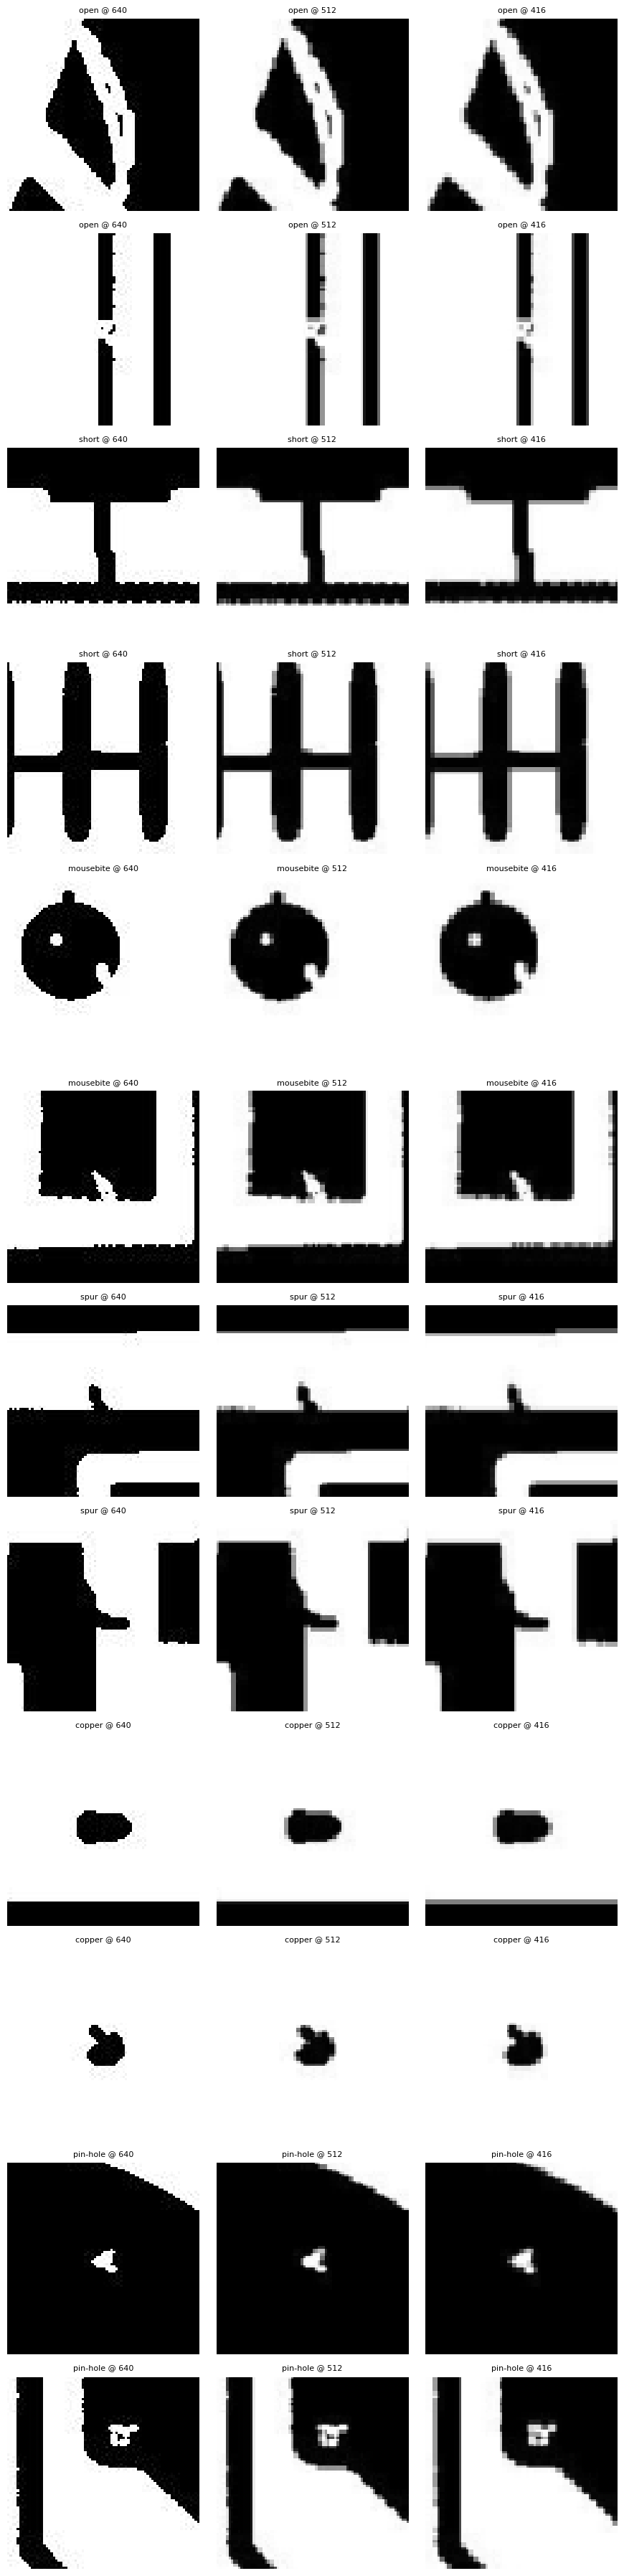

In [ ]:
def downscale_roundtrip(img, size):
    small = Image.fromarray(img).resize((size, size), Image.BILINEAR)
    return np.asarray(small.resize((img.shape[1], img.shape[0]), Image.NEAREST))

SIZES = (640, 512, 416)
rows = []
for name in CLASS_NAMES:
    sub = annotations[annotations["class_name"] == name]
    rows.extend(sub.sample(n=2, random_state=RANDOM_SEED).itertuples())

fig, axes = plt.subplots(len(rows), len(SIZES), figsize=(3 * len(SIZES), 3 * len(rows)))
for r, b in enumerate(rows):
    img = load_gray(path_by_key[b.image_key])
    cx, cy = (b.x1 + b.x2) // 2, (b.y1 + b.y2) // 2
    half = 40
    l = int(np.clip(cx - half, 0, img.shape[1] - 2 * half))
    t = int(np.clip(cy - half, 0, img.shape[0] - 2 * half))
    for c, size in enumerate(SIZES):
        view = img if size == 640 else downscale_roundtrip(img, size)
        axes[r, c].imshow(view[t:t + 2 * half, l:l + 2 * half], cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{b.class_name} @ {size}", fontsize=8)
        axes[r, c].axis("off")
fig.tight_layout()
plt.show()

- With YOLO object detection, you should keep the input at 640 by default, only lower it after measuring recall

Conclusion:
- Keep the current split, remove the image train/01_PCB__1030.jpg
- For the YOLO dataset, keep the original image size of 640
- For the classification dataset, since the boxes vary in size, crop the defective regions according to the boxes so the model can learn defects better, then resize the cropped images to 224
- When training the model, apply geometric augmentation instead of color/brightness

Small limitations: The origin of the split method hasn’t been verified. The data also doesn’t have clean board images, so false positives can’t be measured.